In [6]:
import numpy as np
import pandas as pd


In [7]:
df=pd.read_csv(r"C:\Users\ak038\OneDrive\Desktop\customer_churn_system\data\raw\WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [8]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [9]:
df=df[["gender","Dependents","tenure","InternetService","Contract","MonthlyCharges","TotalCharges","Churn"]]

In [10]:
df.head()

,gender,Dependents,tenure,InternetService,Contract,MonthlyCharges,TotalCharges,Churn
0,Female,No,1,DSL,Month-to-month,29.85,29.85,No
1,Male,No,34,DSL,One year,56.95,1889.5,No
2,Male,No,2,DSL,Month-to-month,53.85,108.15,Yes
3,Male,No,45,DSL,One year,42.30,1840.75,No
4,Female,No,2,Fiber optic,Month-to-month,70.70,151.65,Yes


In [11]:
df["tenure"].describe()

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64

In [12]:
df.columns

Index(['gender', 'Dependents', 'tenure', 'InternetService', 'Contract',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

<Axes: xlabel='MonthlyCharges', ylabel='Count'>

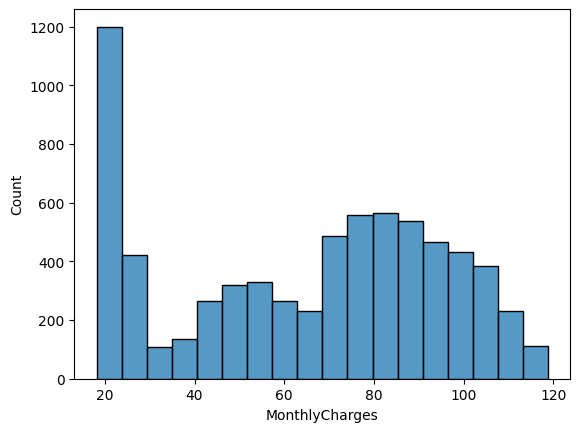

In [13]:
import seaborn as sns
sns.histplot(data=df,x="MonthlyCharges")

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   gender           7043 non-null   str    
 1   Dependents       7043 non-null   str    
 2   tenure           7043 non-null   int64  
 3   InternetService  7043 non-null   str    
 4   Contract         7043 non-null   str    
 5   MonthlyCharges   7043 non-null   float64
 6   TotalCharges     7043 non-null   str    
 7   Churn            7043 non-null   str    
dtypes: float64(1), int64(1), str(6)
memory usage: 667.5 KB


In [15]:
df["TotalCharges"]=pd.to_numeric(df["TotalCharges"],errors="coerce")

In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   gender           7043 non-null   str    
 1   Dependents       7043 non-null   str    
 2   tenure           7043 non-null   int64  
 3   InternetService  7043 non-null   str    
 4   Contract         7043 non-null   str    
 5   MonthlyCharges   7043 non-null   float64
 6   TotalCharges     7032 non-null   float64
 7   Churn            7043 non-null   str    
dtypes: float64(2), int64(1), str(5)
memory usage: 627.1 KB


In [17]:
df=df.dropna(subset=["TotalCharges"])

In [18]:
df.isnull().sum()

gender             0
Dependents         0
tenure             0
InternetService    0
Contract           0
MonthlyCharges     0
TotalCharges       0
Churn              0
dtype: int64

In [19]:
df.columns

Index(['gender', 'Dependents', 'tenure', 'InternetService', 'Contract',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [20]:
x=df.iloc[:,:-1]

In [21]:
x.columns

Index(['gender', 'Dependents', 'tenure', 'InternetService', 'Contract',
       'MonthlyCharges', 'TotalCharges'],
      dtype='str')

In [22]:
y=df.iloc[:,-1].map({"Yes":1,"No":0})

In [23]:
y.head()

0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64

In [24]:
print(x.shape)
print(y.shape)

(7032, 7)
(7032,)


In [25]:
from sklearn.model_selection import train_test_split

In [26]:
##--------Block # 1 splitting Data---------##
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [27]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(5625, 7)
(1407, 7)
(5625,)
(1407,)


In [28]:
x.head(1)

,gender,Dependents,tenure,InternetService,Contract,MonthlyCharges,TotalCharges
0,Female,No,1,DSL,Month-to-month,29.85,29.85


In [29]:
numerical_cols=["tenure","MonthlyCharges","TotalCharges"]
categorical_cols=["gender","Dependents"]
ordered_cols=["Contract"]

In [30]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,OrdinalEncoder,LabelEncoder,RobustScaler

In [31]:
y.head()

0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64

In [32]:
from sklearn.preprocessing import OneHotEncoder,OrdinalEncoder,RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
n_p=Pipeline(steps=[
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",RobustScaler())
])
c_p=Pipeline(steps=[
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("encode",OneHotEncoder(handle_unknown="ignore",sparse_output=False))
])
o_p=Pipeline(steps=[
    ("imput",SimpleImputer(strategy="most_frequent")),
    ("encoder",OrdinalEncoder(categories=[["Month-to-month","One year","Two year"]]))
]
)
preprocessor=ColumnTransformer(transformers=[
    ("num",n_p,numerical_cols),
    ("cat",c_p,categorical_cols),
    ("ord",o_p,ordered_cols)
]
)
f_p=Pipeline(steps=[
    ("preprocessor",preprocessor),
    ("algo",LogisticRegression(max_iter=1000))
])
f_p.fit(x_train,y_train)
y_pred=f_p.predict(x_test)
acc=accuracy_score(y_pred,y_test)
print("Model Trained Successfully")
print(f"The Accuracy is {acc}")


Model Trained Successfully
The Accuracy is 0.7789623312011372


In [33]:
##--------Bloack #2 Sub-pipelines------------##
numerical_pipeline=Pipeline(steps=[
    ("n_imputer",SimpleImputer(strategy="median")),
    ("scaler",RobustScaler())
]
)
categorical_pipeline=Pipeline(steps=[
    ("c_imputer",SimpleImputer(strategy="most_frequent")),
    ("hot_encoder",OneHotEncoder(handle_unknown="ignore",sparse_output=False))
])
ordinal_pipeline=Pipeline(steps=[
    ("o_imputer",SimpleImputer(strategy="most_frequent")),
    ("order_encoder",OrdinalEncoder(categories=[["Month-to-month","One year","Two year"]]))
])



In [34]:
from sklearn.compose import ColumnTransformer

In [35]:
preprocessors=ColumnTransformer(transformers=
    [
        ("numerical",numerical_pipeline,numerical_cols),
        ("categorical",categorical_pipeline,categorical_cols),
        ("ordinal",ordinal_pipeline,ordered_cols)
    ]
)

In [36]:
from sklearn.linear_model import LogisticRegression

In [37]:
final_pipeline=Pipeline(steps=[
    ("preprocessor",preprocessors),
    ("model",LogisticRegression(max_iter=1000))
])

In [38]:
final_pipeline.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numerical', ...), ('categorical', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [39]:
y_pred=final_pipeline.predict(x_test)

In [40]:
from sklearn.metrics import accuracy_score

In [41]:
accuracy_score(y_pred,y_test)

0.7789623312011372

In [42]:
from sklearn.metrics import classification_report,confusion_matrix
from sklearn.model_selection import cross_val_score
print("Classification Report : \n",classification_report(y_pred,y_test))
print("Confusion Matrix :\n",confusion_matrix(y_pred,y_test))

Classification Report : 
               precision    recall  f1-score   support

           0       0.89      0.82      0.86      1126
           1       0.46      0.61      0.53       281

    accuracy                           0.78      1407
   macro avg       0.68      0.72      0.69      1407
weighted avg       0.81      0.78      0.79      1407

Confusion Matrix :
 [[924 202]
 [109 172]]


In [43]:
from sklearn.model_selection import cross_val_score
cval_score=cross_val_score(final_pipeline,x_train,y_train,cv=5,scoring="f1")
print(cval_score)
print(cval_score.mean())

[0.55263158 0.56074766 0.53874539 0.53974122 0.61029412]
0.560431993512547


In [44]:
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

In [46]:
models={
    "LogisticRegression":LogisticRegression(max_iter=1000,class_weight="balanced"),
    "Support Vector Machine(rbf)":SVC(kernel="rbf",class_weight="balanced",random_state=42),
    "Support Vector Machine(linear)":SVC(kernel="linear",class_weight="balanced",random_state=42),
    "K-Neighbors":KNeighborsClassifier(n_neighbors=15),
    "Neural-Network MLP":MLPClassifier(hidden_layer_sizes=(64,32),max_iter=500,random_state=42),
}

for name,model in models.items():
    pipe=Pipeline(steps=[
        ("processors",preprocessors),
        ("model",model),
    ])

cv_f1=cross_val_score(pipe,x_train,y_train,cv=5,scoring="f1").mean()
print(f"{name:22s} -> Mean CV F1-Score {cv_f1:.4f}")

c:\Users\ak038\AppData\Local\miniconda3\envs\Data_analysis\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:788: UserWarning: Training interrupted by user.
  warnings.warn("Training interrupted by user.")


Neural-Network MLP     -> Mean CV F1-Score 0.5693


In [49]:
print("hi")

hi


In [51]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC



In [52]:
model_configs={
"LogisticRegression":{
    "model":LogisticRegression(max_iter=1000,class_weight="balanced"),
    "params":{
        "model__C":[0.1,1.0,10.0]
    },
},
"SVC":{
    "model":SVC(class_weight="balanced",probability=True,random_state=42),
    "params":{
        "model__C":[0.1,1.0,10.0],
        "model__kernel":["rbf","linear"],
    },
},
"KNN":{"model":KNeighborsClassifier(),
       "params":{
           "model__n_neighbors":[5,11,15],
           "model__weights":["uniform","distance"],
       },
       },
"MLP":{"model":MLPClassifier(max_iter=500,early_stopping=True,random_state=42),
       "params":{
           "model__hidden_layer_sizes":[(32,16),(64,32)],
           "model__alpha":[0.001,0.01,0.1]
           
       },},
}


best_pipelines={}

for name,config in model_configs.items():
    pipe=Pipeline(steps=[
        ("preprocessor",preprocessors),
        ("model",config["model"])
    ])

    grid=GridSearchCV(
        estimator=pipe,
        param_grid=config["params"],
        cv=5,
        scoring="f1",
        n_jobs=1

    )

    grid.fit(x_train,y_train)
    best_pipelines[name]=grid.best_estimator_
    print(f"{name:20s} | Best CV F1: {grid.best_score_:.4f} | Params: {grid.best_params_}")


LogisticRegression   | Best CV F1: 0.6097 | Params: {'model__C': 10.0}
SVC                  | Best CV F1: 0.6013 | Params: {'model__C': 10.0, 'model__kernel': 'rbf'}
KNN                  | Best CV F1: 0.5613 | Params: {'model__n_neighbors': 11, 'model__weights': 'uniform'}
MLP                  | Best CV F1: 0.5387 | Params: {'model__alpha': 0.001, 'model__hidden_layer_sizes': (32, 16)}


In [53]:
import joblib
from sklearn.metrics import classification_report, confusion_matrix

# 1. Extract the winning pipeline from your dictionary
final_model = best_pipelines["LogisticRegression"]

# 2. Run final evaluation on the unseen test set (x_test)
y_test_pred = final_model.predict(x_test)

print("Final Test Confusion Matrix:\n", confusion_matrix(y_test, y_test_pred))
print("\nFinal Test Classification Report:\n", classification_report(y_test, y_test_pred))



Final Test Confusion Matrix:
 [[699 334]
 [ 66 308]]

Final Test Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.68      0.78      1033
           1       0.48      0.82      0.61       374

    accuracy                           0.72      1407
   macro avg       0.70      0.75      0.69      1407
weighted avg       0.80      0.72      0.73      1407



In [54]:
# 3. Save the entire tuned pipeline (preprocessor + model) to a file
joblib.dump(final_model, "churn_prediction_pipeline.pkl")
print("Saved winning pipeline successfully!")


Saved winning pipeline successfully!


In [55]:
import json
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score

y_pred = final_model.predict(x_test)
y_prob = final_model.predict_proba(x_test)[:, 1]

metrics = {
    "accuracy": round(float(accuracy_score(y_test, y_pred)), 4),
    "precision": round(float(precision_score(y_test, y_pred)), 4),
    "recall": round(float(recall_score(y_test, y_pred)), 4),
    "f1_score": round(float(f1_score(y_test, y_pred)), 4),
    "roc_auc": round(float(roc_auc_score(y_test, y_prob)), 4),
    "confusion_matrix": confusion_matrix(y_test, y_pred).tolist(),
}

with open("metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)


In [1]:
print("Model is ready to connect with an API")

Model is ready to connect with an API
